# S&P 500 — analiza zmienności, ryzyka i skrajnych ruchów cen

**Projekt portfolio | Python · Pandas**

W tym projekcie analizuję notowania 503 spółek z okresu od stycznia 2010 do maja 2026.

Projekt rozpocząłem od obserwacji SNDK — spółki, której kurs potrafi mocno zmieniać się w krótkim czasie. Chciałem sprawdzić, jak wypada ona na tle powszechnie znanych firm: Procter & Gamble, PepsiCo, Johnson & Johnson, Coca-Coli, McDonald’s i Berkshire Hathaway.

Interesowało mnie przede wszystkim, jak duże są codzienne wahania cen, jak głębokie bywają spadki i ile czasu zajmuje odrobienie strat. Chciałem też sprawdzić, czy spółki o spokojniejszym kursie rzeczywiście doświadczały mniejszych strat.

**Autorstwo i wykorzystanie AI**

Jestem autorem kodu analitycznego oraz koncepcji i przebiegu całej analizy — od sformułowania pytań, przez dobór miar, po porównanie wyników. AI wykorzystałem do wygenerowania kodu wykresów Matplotlib oraz złożenia podsumowania projektu na podstawie mojej analizy.

**Najważniejsze wyniki**

- **SNDK wyróżnia się dużymi wahaniami.** W badanym zbiorze ma najwyższą dzienną zmienność — 6,27%. Dla porównania JNJ ma najniższą — 1,07%, czyli niemal sześciokrotnie mniejszą.
- **Znane firmy znalazły się wśród najmniej zmiennych spółek.** JNJ, KO, PG, PEP i MCD trafiły do dziesiątki o najniższej zmienności w porównaniu bez filtra długości historii.
- **Mniejsze wahania zwykle towarzyszyły płytszym spadkom od wcześniejszego szczytu.** Spokojniejszy kurs nie oznaczał jednak braku ryzyka.
- **Powrót do wcześniejszej ceny może wymagać czasu.** W przykładzie MCO odrobienie strat zajęło 106 dni od dołka. Cały okres od wcześniejszego szczytu do jego odzyskania wyniósł 139 dni.
- **Porównanie obejmuje różne okresy.** Dla SNDK dostępne są 324 ceny, a dla JNJ 4126. Wyniki nie pokazują więc zachowania obu spółek w dokładnie tych samych warunkach.

## 1. Dane i przygotowanie

Dane pochodzą ze zbioru [S&P 500 Daily Update Dataset na Kaggle](https://www.kaggle.com/datasets/yash16jr/s-and-p500-daily-update-dataset), opublikowanego przez użytkownika **yash16jr**. Analizowana kopia obejmuje notowania od 4 stycznia 2010 do 29 maja 2026.

Zbiór zawiera ceny otwarcia i zamknięcia, najwyższe i najniższe ceny sesji oraz wolumen obrotu. Do obliczenia stóp zwrotu wykorzystuję kolumnę `Close`, czyli cenę zamknięcia.

Przygotowanie danych obejmuje uporządkowanie nagłówków, ustawienie odpowiednich typów danych i przekształcenie tabeli tak, aby każdy wiersz odpowiadał jednej spółce w danym dniu. Sprawdzam również braki danych, zakres dat i powtarzające się pary data–spółka. Przed obliczeniami sortuję notowania według spółki i daty.

Porównuję całą dostępną historię każdej spółki. Nie wszystkie firmy mają równie długi okres notowań, dlatego przy interpretacji wyników uwzględniam tę różnicę. Analiza dotyczy spółek dostępnych w zbiorze — nie odtwarza historycznego składu ani wyniku indeksu S&P 500.

Plik wejściowy: `data/SnP_daily_update.csv`. Instrukcja uruchomienia projektu znajduje się w README.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.6f}".format)
df_raw = pd.read_csv("data/SnP_daily_update.csv", header=None, low_memory=False)

In [2]:
#uzywam copy aby moc modyfikowac bez obaw o zmiane raw data
header_1 = df_raw.iloc[0].copy()
header_2 = df_raw.iloc[1].copy()

# cleaning headera kolumny z data
header_1.iloc[0] = "Date"
header_2.iloc[0] = ""

new_columns = pd.MultiIndex.from_arrays([header_1, header_2])

df_wide = df_raw.iloc[3:].copy()

#nowy df, z 2-level header oraz bez pustego wiersza (index 2)
df_wide.columns = new_columns

#przygotowanie do przejscia w format long / ustawienie dat jako indexow

df_wide = df_wide.set_index(("Date", ""))

df_wide.index.name = "Date"

df_wide.index = pd.to_datetime(df_wide.index)

df_wide = df_wide.apply(pd.to_numeric)

df_long = df_wide.stack(level=1).reset_index()

df_long = df_long.rename(columns={1:'Ticker'})

In [3]:
df_long.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075378 entries, 0 to 2075377
Data columns (total 7 columns):
 #   Column  Dtype         
---  ------  -----         
 0   Date    datetime64[us]
 1   Ticker  str           
 2   Close   float64       
 3   High    float64       
 4   Low     float64       
 5   Open    float64       
 6   Volume  float64       
dtypes: datetime64[us](1), float64(5), str(1)
memory usage: 110.8 MB


In [4]:
df_long.isna().sum()

0
Date           0
Ticker         0
Close     121197
High      121197
Low       121197
Open      121197
Volume    121197
dtype: int64

In [5]:
print('Pierwsza data:', df_long['Date'].min())
print('Ostatnia data:', df_long['Date'].max())
print('Liczba spółek:', df_long['Ticker'].nunique())

Pierwsza data: 2010-01-04 00:00:00
Ostatnia data: 2026-05-29 00:00:00
Liczba spółek: 503


Przed obliczeniami uporządkowałem notowania według spółki i daty. Sprawdziłem też braki danych. Tam, gdzie nie ma ceny, pozostawiłem pustą wartość zamiast wpisywać cenę z poprzedniego dnia.

## 2. Dzienne stopy zwrotu

### Jak duże są codzienne zmiany cen?

Dla każdej spółki policzyłem zmianę ceny zamknięcia względem poprzedniej obserwacji. Następnie zebrałem dzienne wyniki wszystkich spółek, aby zobaczyć, jakie zmiany występują najczęściej.

In [6]:
df_long = df_long.sort_values(["Ticker", "Date"]).reset_index(drop=True)
df_long['daily_return'] = (df_long .groupby("Ticker")["Close"] .pct_change(fill_method=None))

In [7]:
return_description = df_long['daily_return'].describe()
return_description.loc[return_description.index != 'count'] *= 100
return_description.round(3)  # count: liczba obserwacji; pozostałe wartości: procenty

count   1953677.000000
mean          0.073000
std           2.024000
min         -53.865000
25%          -0.814000
50%           0.074000
75%           0.965000
max          74.593000
Name: daily_return, dtype: float64

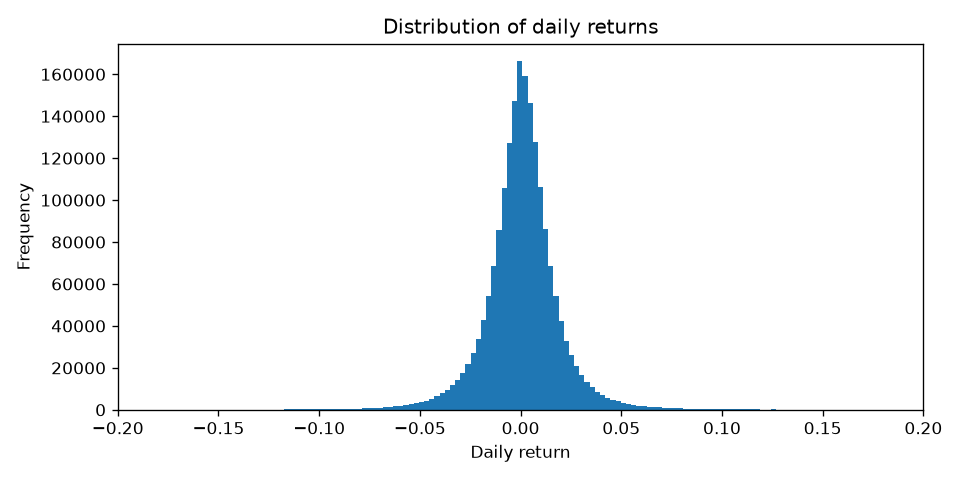

In [8]:
# 1. Histogram dziennych stóp zwrotu

plt.figure(figsize=(8, 4))
plt.hist(df_long['daily_return'].dropna(), bins=500)

plt.xlim(-0.2, 0.2)

plt.title('Distribution of daily returns')
plt.xlabel('Daily return')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Na histogramie możemy zauważyć, że najwięcej dziennych zmian znajduje się blisko zera. Środkowe 50% wyników mieści się między około −0,81% a +0,97%. Duże wzrosty i spadki występują znacznie rzadziej.

Średnia dzienna zmiana wyniosła około 0,073%, a odchylenie standardowe około 2,02%. Nie oznacza to, że każdy dzień przynosił ruch w granicach ±2%. W zbiorze są też znacznie większe zmiany — pokazuję je w dalszej części analizy. Histogram ograniczyłem do przedziału od −20% do +20%, aby środek rozkładu był lepiej widoczny.

## 3. Zmienność i porównanie spółek

### Które spółki mają spokojniejszy kurs, a które większe wahania?

Policzyłem odchylenie standardowe dziennych stóp zwrotu każdej spółki. Im wyższy wynik, tym bardziej zmieniały się jej dzienne zwroty. Porównałem tę miarę z przedziałem między q05 a q95, w którym mieści się środkowe 90% historycznych zmian.

In [9]:
df_ticker_stats = df_long.groupby('Ticker').agg(
        Volatility = ('daily_return' , 'std'),
        Days = ('Close' , 'count')
)

df_ticker_stats['q01'] = df_long.groupby('Ticker')['daily_return'].quantile(0.01)
df_ticker_stats['q99'] = df_long.groupby('Ticker')['daily_return'].quantile(0.99)
df_ticker_stats['q05'] = df_long.groupby('Ticker')['daily_return'].quantile(0.05)
df_ticker_stats['q95'] = df_long.groupby('Ticker')['daily_return'].quantile(0.95)

df_ticker_stats['normal_range'] = ( df_ticker_stats['q95'] - df_ticker_stats['q05'] )

### Spółki z co najmniej pięcioletnią historią

Najpierw wybrałem spółki z przynajmniej 1260 dostępnymi cenami, czyli w przybliżeniu pięcioma latami sesji. Dzięki temu w tym rankingu nie uwzględniam firm z bardzo krótką historią. Okresy notowań nadal mogą się różnić.

In [10]:
stable_companies = df_ticker_stats[df_ticker_stats['Days'] >= 1260].sort_values('Volatility', ascending=True).copy()
stable_companies[:10]

,Volatility,Days,q01,q99,q05,q95,normal_range
Ticker,,,,,,,
JNJ,0.010650,4126,-0.027777,0.027116,-0.015359,0.015721,0.031080
KO,0.010751,4126,-0.029663,0.028222,-0.015484,0.016036,0.031520
PG,0.010909,4126,-0.030261,0.028911,-0.015668,0.015971,0.031640
PEP,0.011160,4126,-0.028198,0.029175,-0.016126,0.016176,0.032302
CL,0.011506,4126,-0.032262,0.027921,-0.016938,0.017340,0.034278
DUK,0.011629,4126,-0.031380,0.028524,-0.016583,0.016984,0.033567
MCD,0.011683,4126,-0.029685,0.030218,-0.016309,0.016765,0.033073
WM,0.011787,4126,-0.032831,0.030611,-0.016334,0.017426,0.033760
KMB,0.011849,4126,-0.031976,0.028914,-0.017701,0.016812,0.034513


### Porównanie 10 najmniej i 10 najbardziej zmiennych spółek

Na wykresie zestawiłem dwie skrajne grupy. Tutaj korzystam z całej dostępnej historii każdej spółki, bez wymogu pięciu lat notowań. Pozwala to uwzględnić również SNDK.

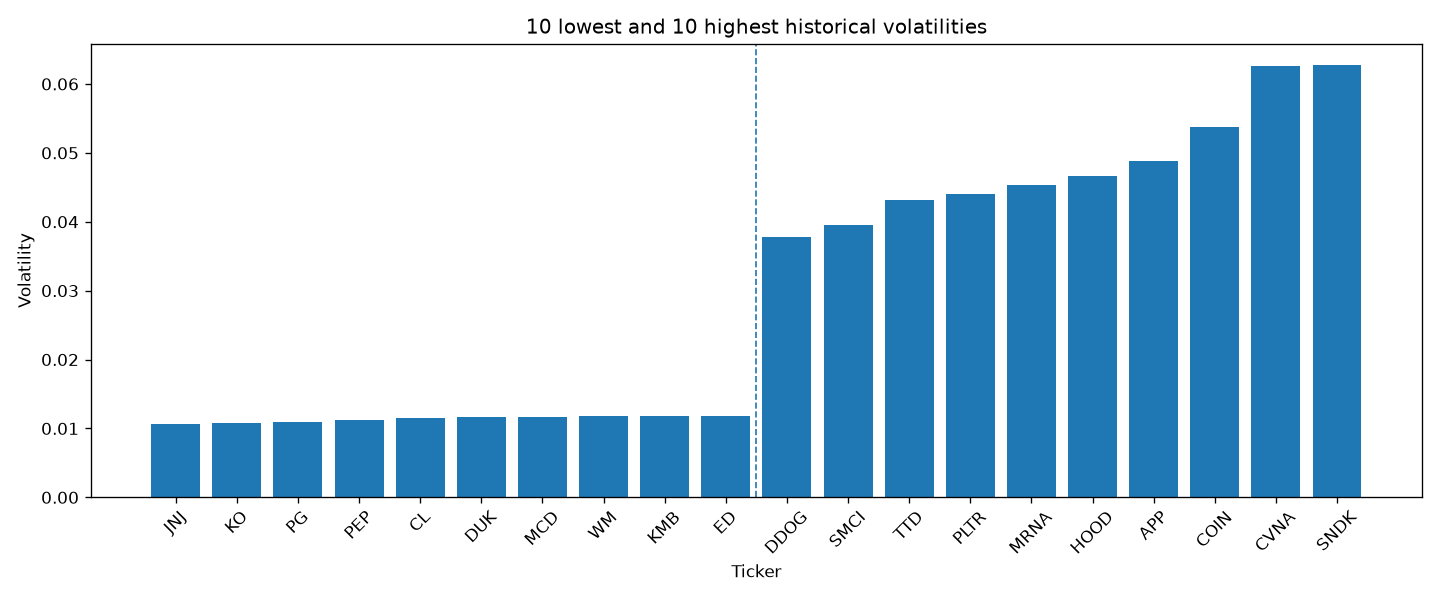

In [11]:
# Top 10 najbardziej stabilnych i najbardziej zmiennych spółek

stable = df_ticker_stats.reset_index().nsmallest(10, 'Volatility')
unstable = (df_ticker_stats.reset_index().nlargest(10, 'Volatility').sort_values('Volatility'))

plot_data = pd.concat([stable, unstable])

plt.figure(figsize=(12, 5))

plt.bar(
    plot_data['Ticker'],
    plot_data['Volatility']
)

plt.axvline(
    x=9.5,
    linestyle='--',
    linewidth=1
)

plt.title('10 lowest and 10 highest historical volatilities')
plt.xlabel('Ticker')
plt.ylabel('Volatility')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Wśród najmniej zmiennych spółek znalazły się powszechnie znane firmy: Johnson & Johnson, Coca-Cola, Procter & Gamble, PepsiCo i McDonald’s. Po drugiej stronie widzimy m.in. SNDK, CVNA, COIN i APP.

SNDK ma najwyższą dzienną zmienność w zbiorze, około 6,27%, a JNJ najniższą, około 1,07%. Różnica jest niemal sześciokrotna. Trzeba jednak pamiętać, że historia SNDK w danych jest znacznie krótsza niż historia JNJ.

### Czy dwie miary zmienności dają podobne wyniki?

Chciałem sprawdzić, czy odchylenie standardowe daje podobną kolejność spółek jak szerokość przedziału q05–q95. Rankingi porównałem dla firm z minimum 1260 cenami, a na wykresie pokazałem wszystkie spółki.

In [12]:
ranking_base = df_ticker_stats[df_ticker_stats['Days'] >= 1260].copy()
ranking_base['volatility_rank'] = ranking_base['Volatility'].rank(method = 'min', ascending=True).astype(int)
ranking_base['normal_range_rank'] = ranking_base['normal_range'].rank(method = 'min', ascending=True).astype(int)

#tworze ranking po jednej i po drugiej metryce aby zobaczyc roznice (powinny wypadac podobnie).

ranking_base['rank_diff'] = (ranking_base['volatility_rank'] - ranking_base['normal_range_rank']).abs()
ranking_base.sort_values('volatility_rank').head(10)

,Volatility,Days,q01,q99,q05,q95,normal_range,volatility_rank,normal_range_rank,rank_diff
Ticker,,,,,,,,,,
JNJ,0.010650,4126,-0.027777,0.027116,-0.015359,0.015721,0.031080,1,1,0
KO,0.010751,4126,-0.029663,0.028222,-0.015484,0.016036,0.031520,2,2,0
PG,0.010909,4126,-0.030261,0.028911,-0.015668,0.015971,0.031640,3,3,0
PEP,0.011160,4126,-0.028198,0.029175,-0.016126,0.016176,0.032302,4,4,0
CL,0.011506,4126,-0.032262,0.027921,-0.016938,0.017340,0.034278,5,9,4
DUK,0.011629,4126,-0.031380,0.028524,-0.016583,0.016984,0.033567,6,7,1
MCD,0.011683,4126,-0.029685,0.030218,-0.016309,0.016765,0.033073,7,5,2
WM,0.011787,4126,-0.032831,0.030611,-0.016334,0.017426,0.033760,8,8,0
KMB,0.011849,4126,-0.031976,0.028914,-0.017701,0.016812,0.034513,9,12,3


In [13]:
ranking_base.sort_values('rank_diff', ascending=False).head(10)

,Volatility,Days,q01,q99,q05,q95,normal_range,volatility_rank,normal_range_rank,rank_diff
Ticker,,,,,,,,,,
PCG,0.030051,4126,-0.061651,0.076678,-0.029276,0.027729,0.057005,466,291,175
VICI,0.018537,2113,-0.044334,0.046601,-0.022714,0.024572,0.047286,257,155,102
SYY,0.016391,4126,-0.046135,0.044911,-0.019707,0.020604,0.040311,155,55,100
GL,0.017843,4126,-0.043253,0.041814,-0.022871,0.022816,0.045687,222,123,99
DRI,0.020094,4126,-0.052080,0.052044,-0.024578,0.026809,0.051387,313,217,96
FISV,0.017256,4125,-0.043066,0.043722,-0.022331,0.022374,0.044705,196,102,94
SPG,0.020146,4126,-0.048559,0.052871,-0.026412,0.025307,0.051719,315,222,93
BIIB,0.024062,4126,-0.052027,0.057200,-0.028618,0.030089,0.058707,403,312,91
STZ,0.018165,4126,-0.042187,0.044748,-0.022887,0.024142,0.047029,238,149,89


In [14]:
ranking_base['Volatility'].corr(ranking_base['normal_range'])

np.float64(0.9834054107367614)

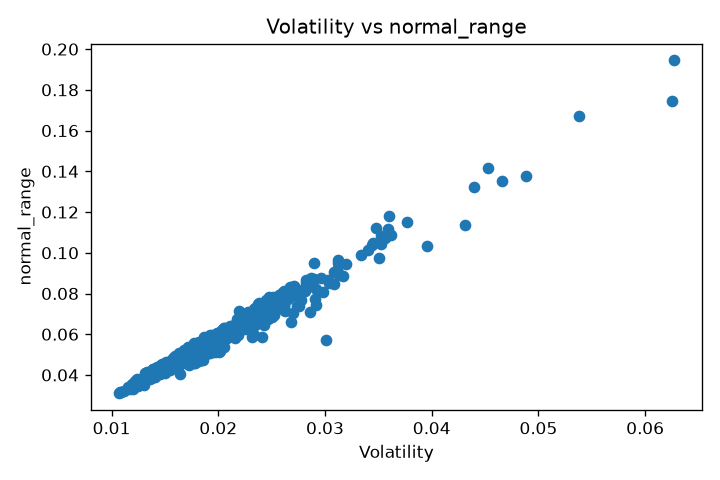

In [15]:
# 4.2 Volatility vs normal_range

plt.figure(figsize=(6, 4))
plt.scatter(df_ticker_stats['Volatility'], df_ticker_stats['normal_range'].abs())
plt.title('Volatility vs normal_range')
plt.xlabel('Volatility')
plt.ylabel('normal_range')
plt.tight_layout()
plt.show()

Możemy zauważyć, że punkty układają się blisko jednej linii. Spółki z wyższym odchyleniem standardowym mają zwykle również szerszy przedział codziennych zmian. Korelacja tych miar wyniosła około 0,98, więc w tej próbie dają podobny ogólny obraz.

Nie oznacza to jednak identycznych rankingów. Przykładem jest PCG, którego pozycja różni się o 175 miejsc. Dlatego jako główną miarę pozostawiłem odchylenie standardowe, a przedział q05–q95 wykorzystuję jako uzupełnienie.

## 4. Skrajne ruchy cen

### Jakie wahania można uznać za nietypowe?

Na to pytanie nie ma jednej odpowiedzi dla wszystkich spółek. Zmiana, która jest duża dla spokojniejszej firmy, może zdarzać się częściej w spółce mocno zmiennej. Najpierw sprawdziłem największe wzrosty i spadki w całym zbiorze, a później porównałem wybrane spółki.

In [16]:
# Największe dzienne wzrosty: obserwacje do weryfikacji
df_long.nlargest(10, 'daily_return')[['Date', 'Ticker', 'daily_return']]

,Date,Ticker,daily_return
1471135,2019-01-24,PCG,0.745932
1650209,2025-08-26,SATS,0.702477
261264,2015-04-13,BLDR,0.676812
1952426,2013-04-19,VRTX,0.619066
575150,2016-07-05,DHR,0.612184
519130,2023-06-08,CVNA,0.560206
1952188,2012-05-07,VRTX,0.553595
108862,2016-04-22,AMD,0.522901
943644,2021-08-04,HOOD,0.504060
1650160,2025-06-16,SATS,0.491093


In [17]:
# Największe dzienne spadki: daty nie są dowodem przyczyny zdarzenia
df_long.nsmallest(10, 'daily_return')[['Date', 'Ticker', 'daily_return']]

,Date,Ticker,daily_return
146971,2020-03-09,APA,-0.538647
861799,2024-04-11,GL,-0.531402
1822127,2020-03-09,TRGP,-0.529074
1471128,2019-01-14,PCG,-0.523593
1454913,2020-03-09,OXY,-0.520138
683849,2022-02-28,EPAM,-0.456763
753493,2020-03-09,FANG,-0.446458
792046,2025-10-29,FISV,-0.440438
1800035,2014-05-16,TKO,-0.434521
519005,2022-12-07,CVNA,-0.429210


### Przykład PCG

In [18]:
df_long.loc[
    (df_long["Date"].between("2019-01-10", "2019-01-30")) &
    (df_long["Ticker"] == "PCG")
]

,Date,Ticker,Close,High,Low,Open,Volume,daily_return
1471126,2019-01-10,PCG,17.506224,18.925648,16.826083,17.792079,24798300.000000,-0.003926
1471127,2019-01-11,PCG,17.338650,17.703362,16.481081,16.757080,19750700.000000,-0.009572
1471128,2019-01-14,PCG,8.260256,9.590965,7.668829,9.078396,127198800.000000,-0.523593
1471129,2019-01-15,PCG,6.811260,7.097116,4.997553,6.190263,173062600.000000,-0.175418
1471130,2019-01-16,PCG,6.929546,7.008403,6.219834,6.357834,78485900.000000,0.017366
1471131,2019-01-17,PCG,6.269121,8.201113,6.219835,8.181400,205294500.000000,-0.095306
1471132,2019-01-18,PCG,7.126688,7.353401,6.446547,6.564832,53590400.000000,0.136792
1471133,2019-01-22,PCG,7.589972,8.260256,6.899975,7.057689,59384900.000000,0.065007
1471134,2019-01-23,PCG,7.875828,7.934971,7.412544,7.846257,21631000.000000,0.037662
1471135,2019-01-24,PCG,13.750663,14.292804,7.195688,7.787114,82538300.000000,0.745932


PCG zwróciło moją uwagę, ponieważ pojawia się w obu zestawieniach. 14 stycznia 2019 r. kurs spadł o około 52%, a dziesięć dni później wzrósł o około 75%.

Tak duży wzrost nie oznacza automatycznie odrobienia wcześniejszych strat. Znaczenie ma cena, od której liczymy każdą zmianę. Z samych notowań możemy opisać przebieg tych ruchów; ustalenie ich przyczyn wymaga sprawdzenia wydarzeń z tego okresu.

### Jak bardzo różnią się SNDK i JNJ?

Najpierw wybrałem spadki SNDK poniżej pierwszego percentyla wszystkich dziennych zwrotów w zbiorze. Potem zestawiłem percentyle liczone osobno dla SNDK i JNJ, aby porównać zakres ich własnych wahań.

In [19]:
df_long[(df_long['daily_return'] < df_long['daily_return'].quantile(0.01)) & (df_long['Ticker'] == 'SNDK')][["Date", 'Ticker', 'daily_return']].sort_values('daily_return')

,Date,Ticker,daily_return
1687245,2025-04-04,SNDK,-0.213016
1687404,2025-11-20,SNDK,-0.203285
1687244,2025-04-03,SNDK,-0.197399
1687454,2026-02-04,SNDK,-0.159538
1687249,2025-04-10,SNDK,-0.150492
1687419,2025-12-12,SNDK,-0.146641
1687399,2025-11-13,SNDK,-0.139633
1687489,2026-03-26,SNDK,-0.110185
1687375,2025-10-10,SNDK,-0.098473
1687472,2026-03-03,SNDK,-0.086693


In [20]:
df_ticker_stats.loc[['SNDK', 'JNJ']]

,Volatility,Days,q01,q99,q05,q95,normal_range
Ticker,,,,,,,
SNDK,0.062722,324,-0.157548,0.168064,-0.067222,0.127312,0.194534
JNJ,0.010650,4126,-0.027777,0.027116,-0.015359,0.015721,0.031080


Różnica jest wyraźna. Środkowe 90% dziennych zmian SNDK mieści się mniej więcej między −6,72% a +12,73%. Dla JNJ ten przedział wynosi około −1,54% do +1,57%. To pokazuje, że ruch duży dla JNJ może mieścić się w znacznie szerszym zakresie zmian SNDK. Porównanie dotyczy dostępnych, różnych okresów historii tych firm.

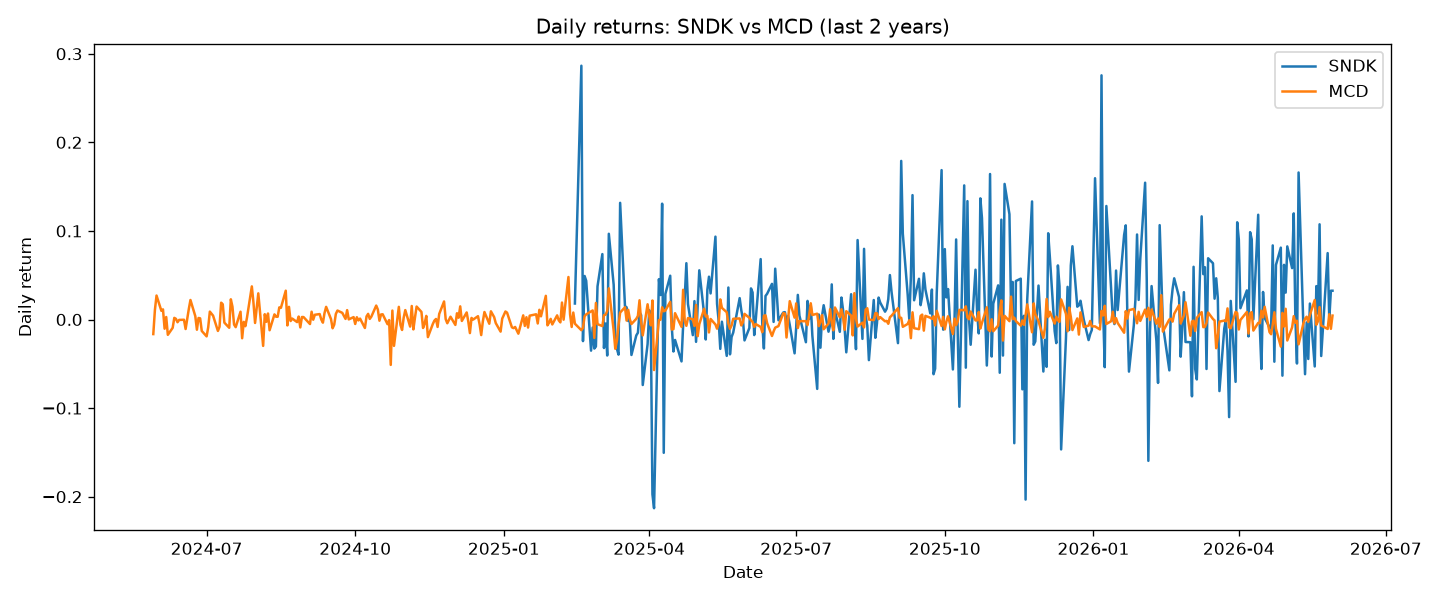

In [21]:
cutoff_date = df_long['Date'].max() - pd.DateOffset(years=2)

sndk = df_long[
    (df_long['Ticker'] == 'SNDK') &
    (df_long['Date'] >= cutoff_date)
]

mcd = df_long[
    (df_long['Ticker'] == 'MCD') &
    (df_long['Date'] >= cutoff_date)
]

plt.figure(figsize=(12, 5))

plt.plot(
    sndk['Date'],
    sndk['daily_return'],
    label='SNDK'
)

plt.plot(
    mcd['Date'],
    mcd['daily_return'],
    label='MCD'
)

plt.title('Daily returns: SNDK vs MCD (last 2 years)')
plt.xlabel('Date')
plt.ylabel('Daily return')

plt.legend()

plt.tight_layout()
plt.show()

Na wykresie porównałem dzienne zmiany McDonald’s i SanDisk w ostatnich dwóch latach zbioru. SNDK ma widoczną krótszą historię, ale w okresie, w którym występują obie spółki, różnica jest duża. Większość zmian MCD skupia się blisko zera, podczas gdy SNDK wielokrotnie notuje dużo większe wzrosty i spadki.

To dobrze pokazuje punkt wyjścia projektu: duże wahanie spokojniejszej spółki nie musi być równie wyjątkowe dla SNDK. Na osi wartość 0,05 oznacza zmianę o 5%.

## 5. Maksymalne obsunięcie i odrabianie strat

### Czy większe wahania oznaczają też głębsze straty?

Samo odchylenie standardowe nie mówi, jak duża mogła być strata od wcześniejszego szczytu. Dlatego dla każdej spółki policzyłem drawdown, czyli spadek od najwyższej ceny osiągniętej wcześniej w dostępnej historii. Następnie wybrałem najgłębszy taki spadek.

In [22]:
df_long['peak_price'] = df_long.groupby('Ticker')['Close'].cummax()
df_long['drawdown'] = df_long['Close'] / df_long['peak_price'] -1

max_drawdown_idx = df_long.groupby('Ticker')['drawdown'].idxmin()
max_drawdown = df_long.loc[max_drawdown_idx,['Ticker', 'Date', 'peak_price', 'Close', 'drawdown' ]].sort_values('drawdown', ascending=True)

df_ticker_stats = df_ticker_stats.reset_index()

df_ticker_stats = df_ticker_stats.merge(max_drawdown[['Ticker','drawdown']], on='Ticker', how='left')

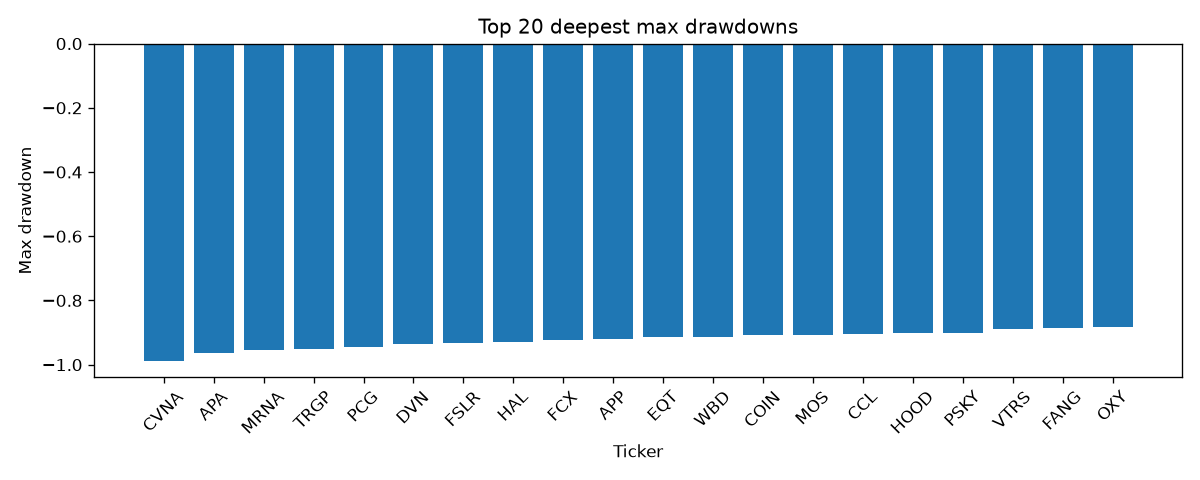

In [23]:
# 3. Top 20 najgłębszych drawdownów

plot_data = df_ticker_stats.nsmallest(20, 'drawdown')

plt.figure(figsize=(10, 4))
plt.bar(plot_data['Ticker'], plot_data['drawdown'])
plt.title('Top 20 deepest max drawdowns')
plt.xlabel('Ticker')
plt.ylabel('Max drawdown')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Najgłębsze obsunięcie odnotowała CVNA — prawie 99% od wcześniejszego szczytu. Pozostałe spółki z tego zestawienia również straciły w najgorszym momencie blisko 90% lub więcej.

Nie chodzi tu o spadek w ciągu jednego dnia. Cena mogła obniżać się przez wiele sesji. To pokazuje ryzyko, którego nie widać, gdy patrzymy tylko na największe roczne wzrosty.

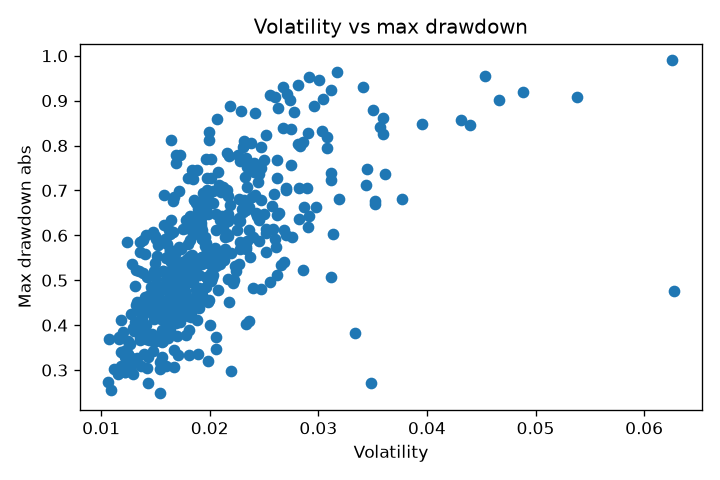

In [24]:
# 4.1 Volatility vs max drawdown

plt.figure(figsize=(6, 4))
plt.scatter(df_ticker_stats['Volatility'], df_ticker_stats['drawdown'].abs())
plt.title('Volatility vs max drawdown')
plt.xlabel('Volatility')
plt.ylabel('Max drawdown abs')
plt.tight_layout()
plt.show()

In [25]:
df_ticker_stats['Volatility'].corr(df_ticker_stats['drawdown'])

np.float64(-0.6644979475428631)

Na wykresie możemy zauważyć, że większej zmienności zwykle towarzyszą głębsze spadki od wcześniejszego szczytu. Korelacja zmienności z ujemnie zapisanym obsunięciem wyniosła około −0,66. Związek jest widoczny, ale nie jest tak silny jak przy porównaniu dwóch miar zmienności.

Spółki o podobnych codziennych wahaniach mogły więc przechodzić przez bardzo różne straty. To pokazuje, dlaczego warto patrzeć na obie miary. Na wykresie głębokość spadku przedstawiam jako liczbę dodatnią — im wyżej leży punkt, tym większe było obsunięcie.

### Jak wypadają wybrane, znane spółki?

Dla KO, PEP, MCD i BRK-B największe obsunięcia wyniosły około 30–37%. W drugiej grupie, obejmującej MRNA, HOOD, APP, COIN i CVNA, przekraczały 90%. Różnica jest duża, ale nawet spokojniejszy kurs nie chronił przed stratą rzędu jednej trzeciej wartości. Każdą spółkę porównuję w jej dostępnej historii.

In [26]:
df_ticker_stats.loc[
    df_ticker_stats['Ticker'].isin(
        {'PEP', 'KO', 'MCD', 'BRK-B'}
        ),
        ['Ticker', 'Volatility', 'drawdown']
        ].sort_values('Volatility')

,Ticker,Volatility,drawdown
272,KO,0.010751,-0.369875
358,PEP,0.011160,-0.303227
297,MCD,0.011683,-0.368986
68,BRK-B,0.012168,-0.295699


In [27]:
df_ticker_stats.loc[
    df_ticker_stats['Ticker'].isin(
        {"APP", "COIN", "CVNA", "HOOD", "MRNA"},
    ),
    ['Ticker', 'Volatility', 'drawdown']
    ].sort_values('Volatility')

,Ticker,Volatility,drawdown
315,MRNA,0.045305,-0.953846
228,HOOD,0.046613,-0.902117
39,APP,0.048878,-0.919025
106,COIN,0.053800,-0.908979
125,CVNA,0.062544,-0.989949


### Ile czasu zajmuje odrobienie strat?

Sprawdziłem to na przykładzie MCO. Policzyłem czas od najniższej ceny podczas największego obsunięcia do odzyskania wcześniejszego szczytu. Osobno sprawdziłem cały okres od tego szczytu do powrotu na ten sam poziom.

In [28]:
ticker = 'MCO'
dd_row = max_drawdown[max_drawdown['Ticker'] == ticker].iloc[0]
dd_date = dd_row['Date']
peak_price = dd_row['peak_price']

recovery_candidates = (df_long[
    (df_long['Close'] >= peak_price) &
    (df_long['Date'] > dd_date) &
    (df_long['Ticker'] == ticker)
    ])

recovery_date = recovery_candidates['Date'].min()

print("Od dołka do odzyskania szczytu:", recovery_date - dd_date)

peaks = df_long[
    (df_long['Date'] < dd_date) &
    (df_long['Ticker'] == ticker) &
    (df_long['Close'] == peak_price)
]

peak_date = peaks['Date'].max()

recovery_time = recovery_date - peak_date

print("Od szczytu do jego odzyskania:", recovery_time)

Od dołka do odzyskania szczytu: 106 days 00:00:00
Od szczytu do jego odzyskania: 139 days 00:00:00


Dla MCO powrót od dołka do wcześniejszego szczytu zajął 106 dni. Od samego szczytu do jego odzyskania minęło 139 dni. To dwa różne spojrzenia na odrabianie strat: samo odbicie od najniższej ceny i cały czas oczekiwania na powrót do punktu wyjścia.

## 6. Wynik po około 12 miesiącach

### Jak bardzo wynik zależy od momentu zakupu?

Dla każdej spółki policzyłem zmianę ceny na przestrzeni 252 obserwacji, czyli w przybliżeniu roku sesyjnego. Dzięki temu mogłem znaleźć jej najlepszy i najgorszy taki okres, zamiast ograniczać się do lat od stycznia do grudnia.

In [29]:
df_long['roll_12m'] = df_long.groupby('Ticker')['Close'].pct_change(periods=252, fill_method=None)

valid_tickers = df_long.groupby('Ticker')['roll_12m'].count()
valid_tickers = valid_tickers[valid_tickers > 0].index

best_idx = df_long[df_long['Ticker'].isin(valid_tickers)].groupby('Ticker')['roll_12m'].idxmax()
worst_idx = df_long[df_long['Ticker'].isin(valid_tickers)].groupby('Ticker')['roll_12m'].idxmin()

df_long['roll_12m_start_date'] = df_long.groupby('Ticker')['Date'].shift(252)
df_long['roll_12m_end_date'] = df_long['Date']

best_rows = df_long.loc[best_idx,['Ticker', 'roll_12m_start_date', 'roll_12m_end_date', 'roll_12m']]
worst_rows = df_long.loc[worst_idx,['Ticker', 'roll_12m_start_date', 'roll_12m_end_date', 'roll_12m']]

best_rows = best_rows.rename(
    columns={
        'roll_12m': 'best_12m',
        'roll_12m_start_date' : 'best_start',
        'roll_12m_end_date' : 'best_end'
        })
worst_rows = worst_rows.rename(
    columns={
        'roll_12m': 'worst_12m',
        'roll_12m_start_date' : 'worst_start',
        'roll_12m_end_date' : 'worst_end'
        })

rolling_summary = best_rows.merge(worst_rows, on='Ticker', how='inner')

In [30]:
rolling_summary.sort_values('best_12m', ascending=False).head(10)

,Ticker,best_start,best_end,best_12m,worst_start,worst_end,worst_12m
407,SNDK,2025-05-07,2026-05-08,43.676577,2025-03-27,2026-03-30,9.826399
282,LITE,2025-04-04,2026-04-08,17.079499,2021-12-28,2022-12-28,-0.534702
125,CVNA,2023-05-03,2024-05-03,16.209335,2021-12-07,2022-12-07,-0.985492
405,SMCI,2023-03-13,2024-03-13,12.307235,2024-04-03,2025-04-04,-0.706372
481,WDC,2025-05-08,2026-05-11,10.694280,2015-05-14,2016-05-13,-0.628133
39,APP,2024-02-13,2025-02-14,10.130918,2021-12-27,2022-12-27,-0.902933
445,TSLA,2019-08-30,2020-08-31,10.043837,2022-01-03,2023-01-04,-0.715848
323,MU,2025-05-28,2026-05-29,9.119820,2015-02-11,2016-02-11,-0.687621
315,MRNA,2020-02-12,2021-02-11,8.649658,2024-05-23,2025-05-28,-0.841168
93,CIEN,2025-04-04,2026-04-08,8.233832,2011-05-19,2012-05-18,-0.561450


In [31]:
rolling_summary.sort_values('worst_12m', ascending=True).head(10)

,Ticker,best_start,best_end,best_12m,worst_start,worst_end,worst_12m
125,CVNA,2023-05-03,2024-05-03,16.209335,2021-12-07,2022-12-07,-0.985492
356,PCG,2019-10-28,2020-10-27,1.607895,2018-10-25,2019-10-28,-0.919780
39,APP,2024-02-13,2025-02-14,10.130918,2021-12-27,2022-12-27,-0.902933
197,FSLR,2012-06-04,2013-06-06,3.337134,2011-06-02,2012-06-01,-0.902356
106,COIN,2022-12-27,2023-12-28,4.707810,2021-12-27,2022-12-27,-0.883505
35,APA,2020-03-17,2021-03-17,3.748015,2019-04-02,2020-04-01,-0.878387
440,TRGP,2020-03-18,2021-03-18,6.009872,2019-03-19,2020-03-18,-0.872206
324,NCLH,2020-03-18,2021-03-18,2.725869,2019-03-19,2020-03-18,-0.861522
182,FANG,2020-03-18,2021-03-18,4.002957,2019-03-19,2020-03-18,-0.847333
228,HOOD,2024-08-05,2025-08-07,5.774056,2021-08-04,2022-08-04,-0.845433


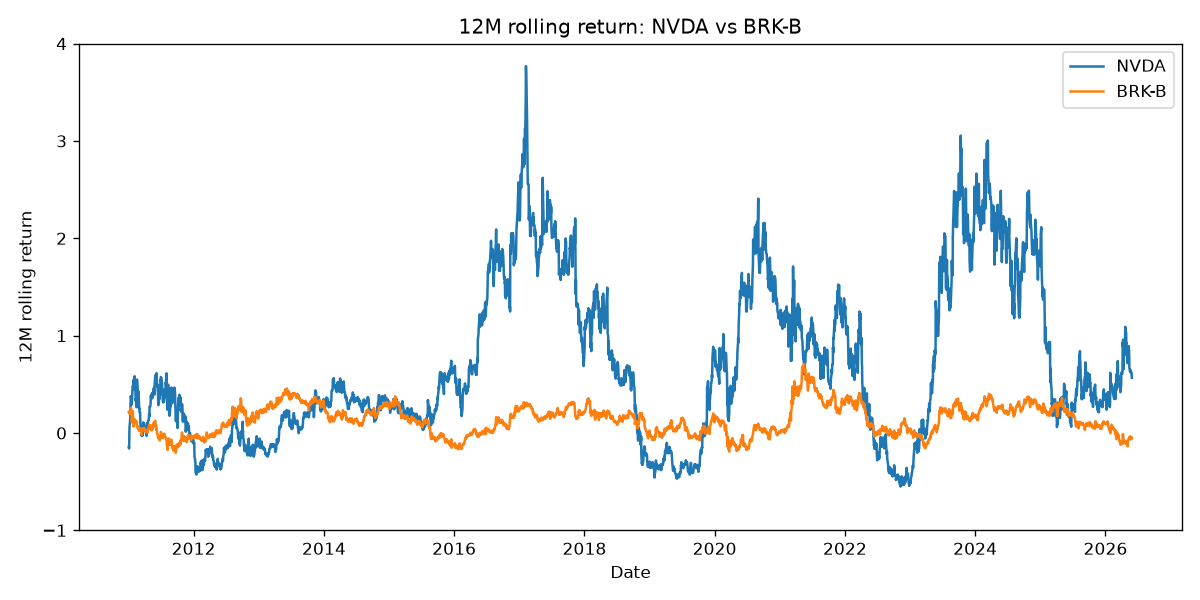

In [32]:
# 6 Rolling 12M return 2 spółek (NVidia oraz Berkshire)

tickers = ['NVDA', 'BRK-B']

plt.figure(figsize=(10, 5))

for ticker in tickers:
    plot_data = df_long[df_long['Ticker'] == ticker]

    plt.plot(
        plot_data['Date'],
        plot_data['roll_12m'],
        label=ticker
    )

plt.ylim(-1, 4)

plt.title('12M rolling return: NVDA vs BRK-B')
plt.xlabel('Date')
plt.ylabel('12M rolling return')

plt.legend()

plt.tight_layout()
plt.show()

Porównałem wynik po około 12 miesiącach dla Berkshire Hathaway i Nvidii. Linia Berkshire przebiega spokojniej, natomiast dla Nvidii widać znacznie większe różnice między okresami — od strat do wzrostów liczonych w setkach procent.

Większa zmienność oznaczała więc zarówno szansę na wyższy wynik, jak i ryzyko zakupu w mniej korzystnym momencie. W obu przypadkach znaczenie miała data rozpoczęcia inwestycji. Oś wykresu obejmuje wyniki od −100% do +400%.

## 7. Wnioski

Poniższe ustalenia wynikają z obliczeń przedstawionych w projekcie i odnoszą się do badanego zbioru.

- **Zakres:** 503 tickerów, od 2010-01-04 do 2026-05-29. Po przekształceniu: 2,075,378 wierszy, w tym 121,197 bez ceny Close. Nie wykryto powtórzeń par data–ticker. Braki nie zostały automatycznie wypełnione.
- **Zmienność:** w rankingu bez filtra historii najniższa dzienna zmienność występuje dla **JNJ (1.07%)**, a najwyższa dla **SNDK (6.27%)**. Lista grup wynika z danych, nie z przyjętych etykiet branżowych. Dostępne liczby cen to odpowiednio 4126 i 324, więc nie jest to porównanie wspólnego okresu.
- **Dwie miary rozproszenia:** korelacja odchylenia standardowego i szerokości q05–q95 dla spółek z minimum 1260 cen wynosi **0.9834**. Obie miary są silnie liniowo związane w tej próbie; tabela różnic rankingów pokazuje, że nie dają identycznych pozycji.
- **Obsunięcia:** korelacja zmienności z ujemną wartością maksymalnego obsunięcia wynosi **-0.6645**. Najgłębsze obsunięcie w dostępnej historii dotyczy **CVNA (-98.99%, dołek 2022-12-27)**. Zależność historyczna nie wyjaśnia przyczyn ani nie gwarantuje przyszłych wyników.
- **Skrajne dni:** największy wzrost to **PCG, 2019-01-24: 74.59%**, a największy spadek to **APA, 2020-03-09: -53.86%**. Są to punkty do weryfikacji, a nie automatyczne błędy lub udowodnione skutki wydarzeń.
- **Odrabianie strat:** dla MCO odzyskanie szczytu po maksymalnym obsunięciu nastąpiło 2020-07-07; od dołka upłynęło 106 dni, a od wcześniejszego szczytu 139 dni. To wynik jednego przypadku.
- **Wynik zależy od okresu:** tabele najlepszych i najgorszych okien 252 obserwacji oraz porównanie NVDA–BRK-B pokazują, dlaczego pojedynczy wynik roczny nie wystarcza do opisu zachowania spółki. Nie traktuję przykładów jako wyniku całych grup.

### Co warto uwzględnić przy czytaniu wyników?

- Spółki mają różne okresy notowań. Dłuższa historia daje więcej okazji do zaobserwowania dużego spadku.
- Niska zmienność nie oznacza braku ryzyka. Nawet znane, spokojniejsze spółki przechodziły przez duże straty.
- Analiza dotyczy firm dostępnych w pliku. Nie odtwarza całego historycznego składu indeksu, w tym firm, które wcześniej z niego wypadły.
- Sposób korekty cen o splity i dywidendy wymaga potwierdzenia. Duże ruchy warto dodatkowo sprawdzić.
- Wyniki opisują przeszłość. Nie sprawdzałem, czy pozwalają przewidzieć przyszłe zmiany cen.

Projekt pozwolił mi przejść od przygotowania danych do porównania spółek i interpretacji wyników. Najważniejszy wniosek jest prosty: warto patrzeć jednocześnie na codzienne wahania, głębokość strat i czas ich odrabiania.

## Dodatek A. Wyniki roczne

### Które spółki osiągały najwyższe wyniki w poszczególnych latach?

Policzyłem zmianę między pierwszą i ostatnią dostępną ceną każdego roku. Następnie sprawdziłem, które spółki trafiały do TOP5 oraz jakie były najlepsze lata poszczególnych firm. Wykres najlepszych lat nie obejmuje niepełnego 2026 r. Wcześniejsze lata również mogą być niepełne, np. w przypadku debiutu spółki.

W tabeli częstości TOP5 liczba lat oznacza liczbę pozycji rocznych w tabeli, a nie potwierdzoną liczbę pełnych lat notowań. Z tego powodu nie traktuję tej częstości jako oceny regularności wyników.

In [33]:
df_long['year'] = df_long['Date'].dt.year
df_annual_returns = (
    df_long.groupby(['Ticker', 'year']).agg(
        first_close = ('Close', 'first'),
        last_close = ('Close', 'last'),
        days = ('Close', 'count')
    )
)
df_annual_returns['annual_return'] = (
    df_annual_returns['last_close'] 
    / df_annual_returns['first_close'] 
    -1
)

In [34]:
top_5_per_year = df_annual_returns[df_annual_returns.groupby('year')['annual_return'].rank(ascending = False) <= 5].sort_values(['year', 'annual_return'], ascending=[True, False])
top_5_per_year.head()

top_5_stable = top_5_per_year.groupby('Ticker').agg(
    top5_count = ('annual_return', 'size')
)

top_5_stable['years_present'] = df_annual_returns.groupby('Ticker').size()
top_5_stable['top5_rate'] = (
    top_5_stable['top5_count']
    / top_5_stable['years_present']
)

top5_growth = top_5_stable.copy()
del top_5_stable
top5_per_year = top_5_per_year.copy()
del top_5_per_year

top5_growth = top5_growth.sort_values('top5_rate', ascending=False)

#filter przynajmniej 8 lat (dane sa z 16) istnienia na gieldzie aby wyeliminowac chwilowe gwiazdy i zostawic jedynie te spolki ktore dlugotrwale są wzrostowe
top5_growth = top5_growth[top5_growth['years_present'] >=8]

top5_growth.head(10)

,top5_count,years_present,top5_rate
Ticker,,,
CVNA,4,17,0.235294
MU,3,17,0.176471
NVDA,3,17,0.176471
NFLX,3,17,0.176471
SNDK,2,17,0.117647
AMD,2,17,0.117647
TPL,2,17,0.117647
MRNA,2,17,0.117647
APP,2,17,0.117647


In [35]:
df_annual_returns = df_annual_returns.reset_index()

df_annual_returns_full_years = df_annual_returns[df_annual_returns['year'] < 2026]
best_years = df_annual_returns_full_years.loc[df_annual_returns_full_years.groupby('Ticker')['annual_return'].idxmax()]
worst_years = df_annual_returns_full_years.loc[df_annual_returns_full_years.groupby('Ticker')['annual_return'].idxmin()]

best_years = best_years.sort_values('annual_return', ascending=False).reset_index(drop=True)
worst_years = worst_years.sort_values('annual_return', ascending=True).reset_index(drop=True)

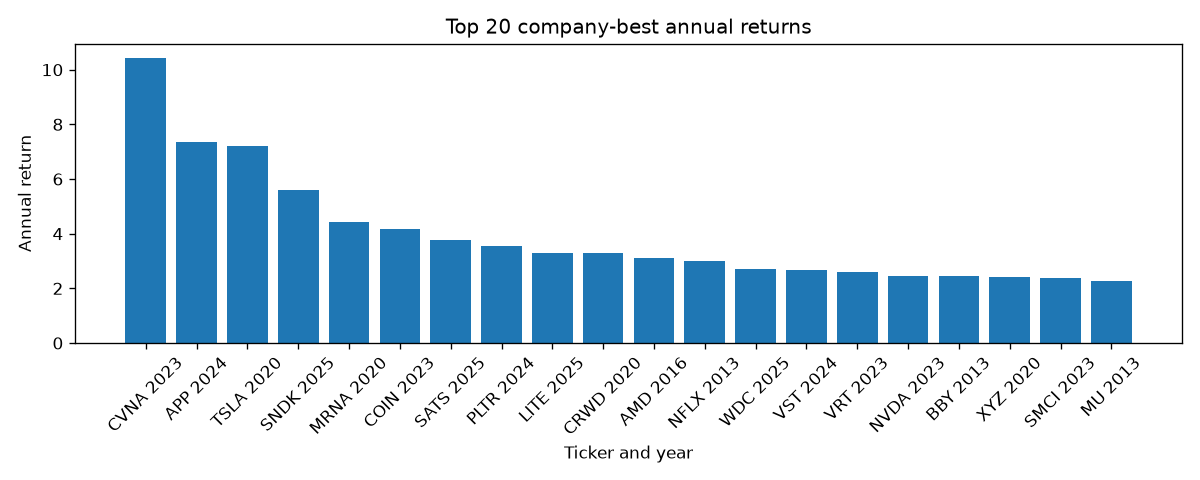

In [36]:
# 7. Największe spośród najlepszych wyników rocznych poszczególnych spółek

plot_data = best_years.nlargest(20, 'annual_return').copy()
plot_data['label'] = plot_data['Ticker'] + ' ' + plot_data['year'].astype(str)

plt.figure(figsize=(10, 4))
plt.bar(plot_data['label'], plot_data['annual_return'])
plt.title('Top 20 company-best annual returns')
plt.xlabel('Ticker and year')
plt.ylabel('Annual return')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Na wykresie widać najlepszy rok każdej z wybranych spółek. W czołówce znalazły się m.in. CVNA, APP, TSLA i SNDK. Najwyższe wyniki pozwalały kilkukrotnie zwiększyć początkową kwotę, ale były to wybrane najlepsze okresy, a nie wynik powtarzający się co roku.

To zestawienie pokazuje potencjał dużych wzrostów. Wcześniejsze wykresy obsunięć pokazują drugą stronę: część tych samych spółek przechodziła również bardzo głębokie spadki.

## Dodatek B. Najlepsze i najgorsze okresy kończące się w danym roku

### Jak zmieniały się rekordowe wyniki po około 12 miesiącach?

Dla każdego roku wybrałem największy i najmniejszy zwrot z okna 252 obserwacji, którego koniec przypadał w tym roku. Okno może więc zaczynać się w poprzednim roku; nie musi obejmować okresu od stycznia do grudnia.

In [37]:
best_rolling_by_year = (df_long.loc[df_long[df_long['roll_12m'].notna()].groupby(['year'])['roll_12m'].idxmax()]
                        [['Ticker', 'year', 'roll_12m_start_date', 'roll_12m_end_date', 'roll_12m']]).sort_values(['year', 'roll_12m'], ascending=[True, False])

worst_rolling_by_year = (df_long.loc[df_long[df_long['roll_12m'].notna()].groupby(['year'])['roll_12m'].idxmin()]
                        [['Ticker', 'year', 'roll_12m_start_date', 'roll_12m_end_date', 'roll_12m']]).sort_values(['year', 'roll_12m'], ascending=[True, True])

In [38]:
best_rolling_by_year

,Ticker,year,roll_12m_start_date,roll_12m_end_date,roll_12m
1906496,URI,2011,2010-02-19,2011-02-17,3.719773
260631,BLDR,2012,2011-10-03,2012-10-02,3.970874
1841137,TSLA,2013,2012-09-26,2013-09-30,6.021423
1841239,TSLA,2014,2013-02-26,2014-02-26,6.348244
199441,AXON,2015,2014-07-17,2015-07-17,2.238095
109030,AMD,2016,2015-12-21,2016-12-20,3.549407
109066,AMD,2017,2016-02-12,2017-02-13,6.371584
1801134,TKO,2018,2017-09-26,2018-09-26,3.239596
1854922,TTD,2019,2018-05-02,2019-05-03,3.701256
1842879,TSLA,2020,2019-08-30,2020-08-31,10.043837


In [39]:
worst_rolling_by_year

,Ticker,year,roll_12m_start_date,roll_12m_end_date,roll_12m
813317,FSLR,2011,2010-12-20,2011-12-19,-0.769359
813430,FSLR,2012,2011-06-02,2012-06-01,-0.902356
108094,AMD,2013,2012-04-02,2013-04-05,-0.720732
1354358,NEM,2014,2013-02-06,2014-02-06,-0.515687
760605,FCX,2015,2014-08-26,2015-08-26,-0.774343
760701,FCX,2016,2015-01-13,2016-01-13,-0.819327
814646,FSLR,2017,2016-04-04,2017-04-03,-0.608418
1471090,PCG,2018,2017-11-15,2018-11-15,-0.681107
1471327,PCG,2019,2018-10-25,2019-10-28,-0.919780
146988,APA,2020,2019-04-02,2020-04-01,-0.878387


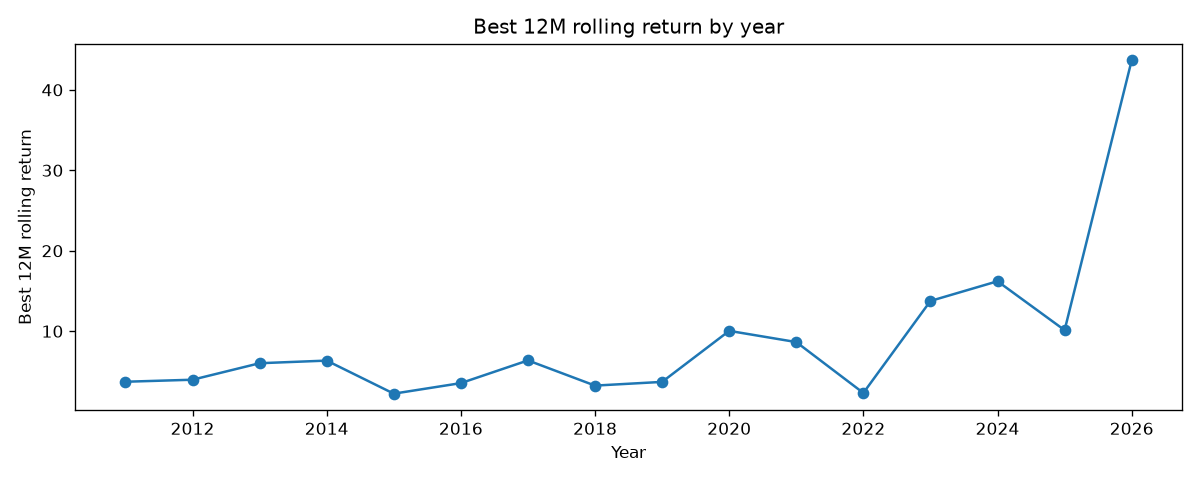

In [40]:
# 8. Najlepszy rolling 12M wynik kończący się w każdym roku

plot_data = best_rolling_by_year.copy()

plt.figure(figsize=(10, 4))
plt.plot(plot_data['year'], plot_data['roll_12m'], marker='o')
plt.title('Best 12M rolling return by year')
plt.xlabel('Year')
plt.ylabel('Best 12M rolling return')
plt.tight_layout()
plt.show()

Najbardziej wyróżnia się wynik SNDK w oknie od 7 maja 2025 do 8 maja 2026: zwrot wyniósł około 4368%. Oznacza to wzrost końcowej wartości do około 44,7-krotności kwoty początkowej. Tak skrajny wynik warto dodatkowo sprawdzić w danych źródłowych.

W późniejszych latach pojawiają się wyższe rekordy niż w początkowej części zbioru, ale nie jest to stały wzrost z roku na rok — w 2022 r. widzimy wyraźny spadek. Każdy punkt dotyczy najlepszego okna jednej spółki, często innej niż rok wcześniej. Nie jest to wynik całej giełdy ani dowód, że rynek jako całość staje się bardziej nieprzewidywalny.

## Dodatek C. Dodatkowe porównania

Sprawdziłem, które spółki pojawiają się jednocześnie w rankingach zmienności i największych obsunięć. Dla wysokiej zmienności i głębokich spadków porównałem po 20 firm, a dla niskiej zmienności i płytkich spadków po 10.

Na końcu pokazuję też ceny TSLA i PG, aby zobaczyć przebieg notowań dwóch różnych spółek.

In [41]:
vol_worst = set(df_ticker_stats.nlargest(20, 'Volatility')['Ticker'])
dd_worst = set(df_ticker_stats.nsmallest(20, 'drawdown')['Ticker'])
vol_best = set(df_ticker_stats.nsmallest(10, 'Volatility')['Ticker'])
dd_best = set(df_ticker_stats.nlargest(10, 'drawdown')['Ticker'])

print("Wspólne: wysoka zmienność i głębokie obsunięcia:", sorted(vol_worst & dd_worst))
print("Różne elementy tych rankingów:", sorted((vol_worst | dd_worst) - (vol_worst & dd_worst)))
print("Wspólne: niska zmienność i płytkie obsunięcia:", sorted(vol_best & dd_best))
print("Różne elementy tych rankingów:", sorted((vol_best | dd_best) - (vol_best & dd_best)))

Wspólne: wysoka zmienność i głębokie obsunięcia: ['APP', 'COIN', 'CVNA', 'HOOD', 'MRNA']
Różne elementy tych rankingów: ['AMD', 'APA', 'BLDR', 'CCL', 'CRWD', 'DASH', 'DDOG', 'DVN', 'EQT', 'FANG', 'FCX', 'FSLR', 'HAL', 'LITE', 'MOS', 'NCLH', 'OXY', 'PCG', 'PLTR', 'PSKY', 'Q', 'SMCI', 'SNDK', 'TRGP', 'TSLA', 'TTD', 'VRT', 'VTRS', 'WBD', 'XYZ']
Wspólne: niska zmienność i płytkie obsunięcia: ['CL', 'JNJ', 'PG']
Różne elementy tych rankingów: ['AEE', 'AMGN', 'BRK-B', 'CMS', 'DUK', 'ED', 'EXE', 'KMB', 'KO', 'MCD', 'PEP', 'Q', 'VLTO', 'WM']


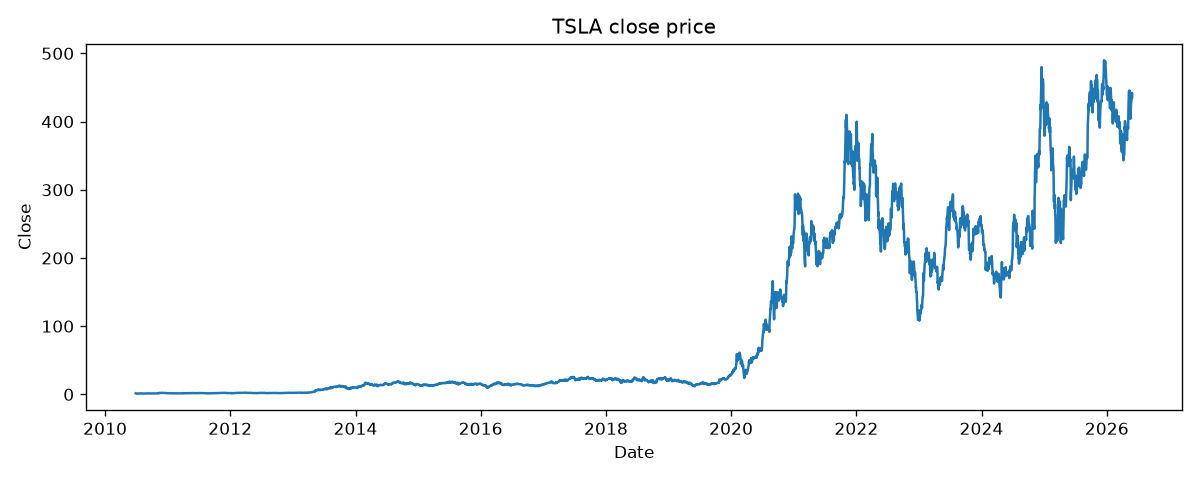

In [42]:
# 5.1 Cena zamknięcia wybranej spółki (TESLA)

selected_ticker = 'TSLA'
plot_data = df_long[df_long['Ticker'] == selected_ticker]

plt.figure(figsize=(10, 4))
plt.plot(plot_data['Date'], plot_data['Close'])
plt.title(f'{selected_ticker} close price')
plt.xlabel('Date')
plt.ylabel('Close')
plt.tight_layout()
plt.show()

Cena TSLA na przestrzeni czasu mocno rosła, ale po drodze pojawiały się duże spadki i odbicia. Sam wysoki wynik między początkiem a końcem wykresu nie pokazuje więc, jak zmienna była droga do tego wyniku.

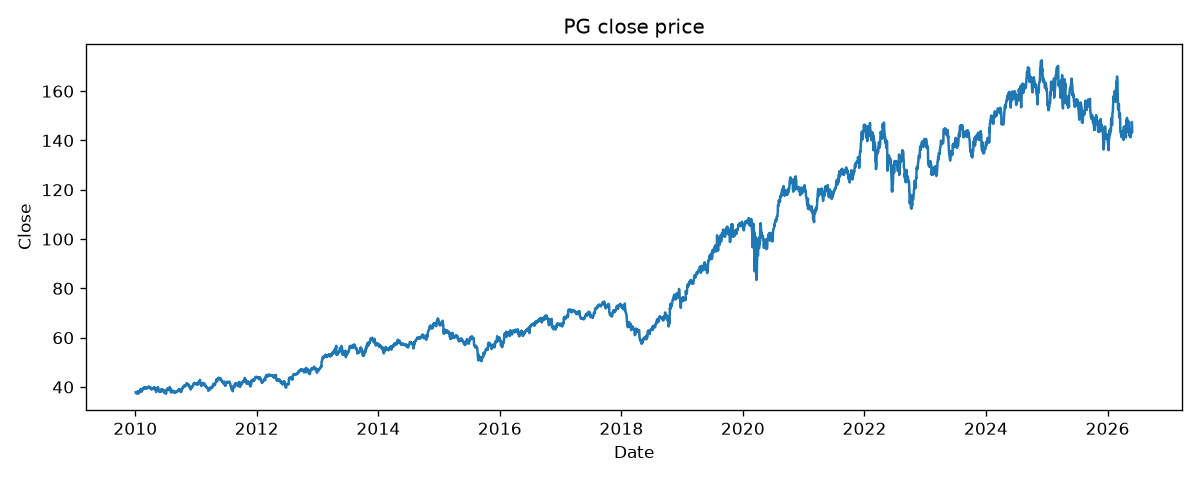

In [43]:
# 5.2 Cena zamknięcia wybranej spółki (Procter & Gamble)

selected_ticker = 'PG'
plot_data = df_long[df_long['Ticker'] == selected_ticker]

plt.figure(figsize=(10, 4))
plt.plot(plot_data['Date'], plot_data['Close'])
plt.title(f'{selected_ticker} close price')
plt.xlabel('Date')
plt.ylabel('Close')
plt.tight_layout()
plt.show()

Przebieg ceny PG jest spokojniejszy niż TSLA, choć również widać okresy spadków. To pasuje do wcześniejszego porównania zmienności. Wykresy mają różne skale cen, dlatego porównuję przebieg notowań, a nie samą wysokość linii.